,track_name,artist,duration_min
710,Lost Boy,Jaden,9.497883
610,I'm Getting Ready,Tasha Cobbs Leonard,8.436667
64,Mirrors,Justin Timberlake,8.069100
63,What Goes Around.../...Comes Around (Interlude),Justin Timberlake,7.476217
622,Achilles Come Down,Gang of Youths,7.035767
689,Never Let Go (Of Me),Baltra,6.909833
682,House Of Balloons / Glass Table Girls,The Weeknd,6.753550
549,Stan,Eminem,6.735100
671,Galvanize,The Chemical Brothers,6.563550
37,After Hours,The Weeknd,6.017100


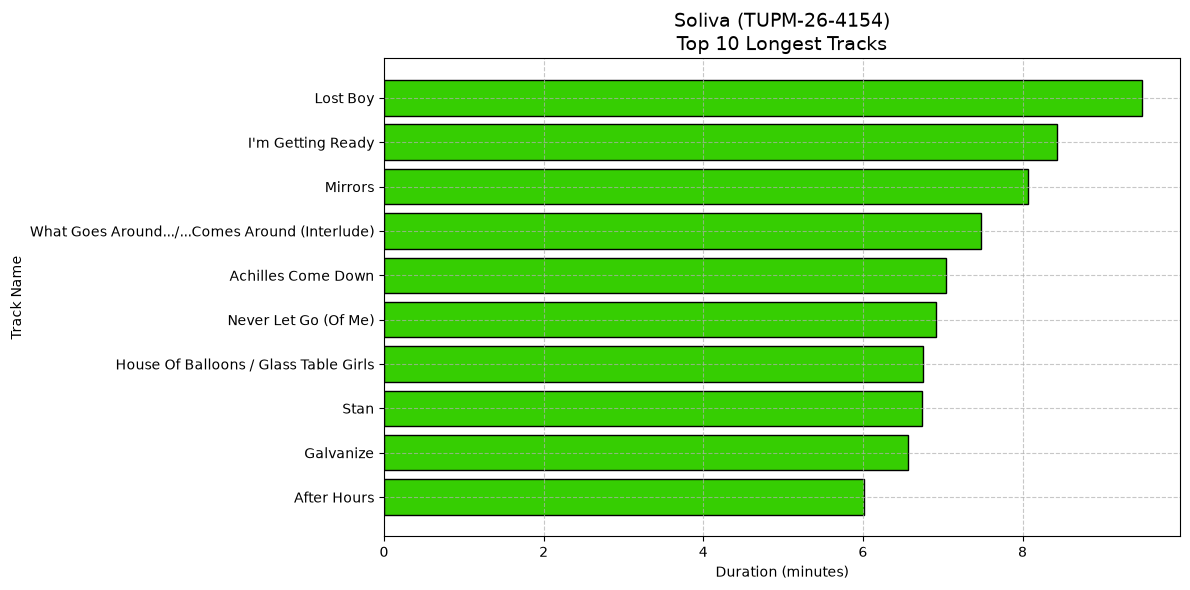

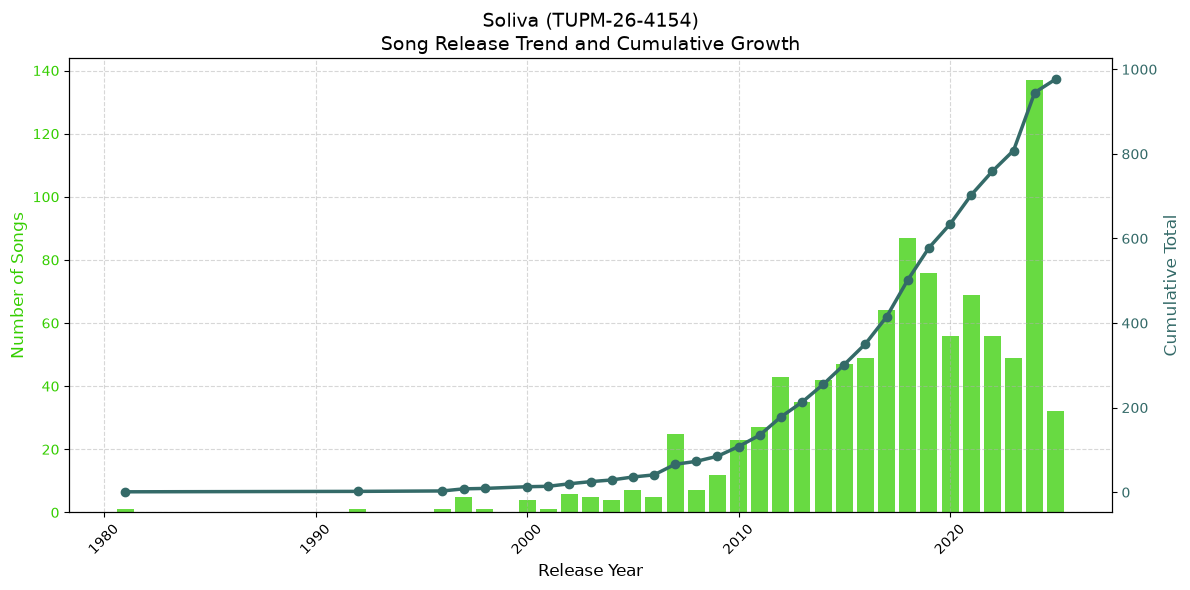

GIF saved successfully at: d:\Downloads\BSECE-1C, 1st Sem\ComProg\Lab8_Data_Visualization_Soliva\animated_hexbin_density.gif


In [4]:
# Appendix: Additional Exercises & Visualization Notes

# Appendix: Additional Exercises & Visualization Notes

# Student: Elgin Matthew De Chavez Soliva
# Student ID: TUPM-26-4154
# Dataset: Top 1000 Most Played Spotify Songs of All Time
# Personalized colors: #32ce02 | #346a68 | coolwarm

import os
import webbrowser
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import pandas as pd
import seaborn as sns

df = pd.read_csv("spotify_top_1000_tracks.csv", encoding="utf-8")

student_name = "Soliva"
student_id = "TUPM-26-4154"
id_num = int(student_id[-3:])  # 154
color_bar = f"#{(id_num * 7) % 256:02x}{(id_num * 3) % 256:02x}{(id_num * 5) % 256:02x}"   # #32ce02
color_line = f"#{(id_num * 2) % 256:02x}{(id_num * 9) % 256:02x}{(id_num * 4) % 256:02x}"  # #346a68
cmap_color = "coolwarm"

# Exercise 1: Top 10 Longest Tracks
longest_tracks = df.nlargest(10, "duration_min")
display(longest_tracks[["track_name", "artist", "duration_min"]])

plt.figure(figsize=(12, 6))
plt.barh(
    longest_tracks["track_name"],
    longest_tracks["duration_min"],
    color=color_bar,
    edgecolor="black",
)
plt.title(f"{student_name} ({student_id})\nTop 10 Longest Tracks", fontsize=14)
plt.xlabel("Duration (minutes)")
plt.ylabel("Track Name")
plt.gca().invert_yaxis()
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# Exercise 2: Song Release Trend and Cumulative Growth
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["year"] = df["release_date"].dt.year
yearly_counts = df.dropna(subset=["year"]).groupby("year").size().reset_index(name="count")
yearly_counts["year"] = yearly_counts["year"].astype(int)
yearly_counts = yearly_counts.sort_values("year")
yearly_counts["cumulative"] = yearly_counts["count"].cumsum()

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.bar(
    yearly_counts["year"],
    yearly_counts["count"],
    color=color_bar,
    alpha=0.75,
    label="Yearly Count",
)
ax1.set_xlabel("Release Year", fontsize=12)
ax1.set_ylabel("Number of Songs", color=color_bar, fontsize=12)
ax1.tick_params(axis="y", labelcolor=color_bar)
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(
    yearly_counts["year"],
    yearly_counts["cumulative"],
    color=color_line,
    linewidth=2.5,
    marker="o",
    label="Cumulative Growth",
)
ax2.set_ylabel("Cumulative Total", color=color_line, fontsize=12)
ax2.tick_params(axis="y", labelcolor=color_line)

plt.title(f"{student_name} ({student_id})\nSong Release Trend and Cumulative Growth", fontsize=14)
ax1.grid(True, linestyle="--", alpha=0.5)
fig.tight_layout()
plt.show()

# Exercise 3: Animated Hexbin Density Map
df_anim = df.dropna(subset=["year", "duration_min", "popularity"]).copy()
df_anim["year"] = df_anim["year"].astype(int)
years_sorted = sorted(df_anim["year"].unique())

fig_anim, ax_anim = plt.subplots(figsize=(10, 6))

def animate_hexbin(i):
    ax_anim.clear()
    current_year = years_sorted[i]
    subset = df_anim[df_anim["year"] <= current_year]
    hb = ax_anim.hexbin(
        subset["duration_min"],
        subset["popularity"],
        gridsize=20,
        cmap=cmap_color,
        mincnt=1,
        alpha=0.85,
    )
    ax_anim.set_xlim(df_anim["duration_min"].min() - 0.5, df_anim["duration_min"].max() + 0.5)
    ax_anim.set_ylim(-5, 105)
    ax_anim.set_title(
        f"{student_name} ({student_id})\nAnimated Hexbin Density (Up to Year: {current_year})",
        fontsize=14,
    )
    ax_anim.set_xlabel("Duration (minutes)")
    ax_anim.set_ylabel("Popularity Score")
    return (hb,)

anim = FuncAnimation(fig_anim, animate_hexbin, frames=len(years_sorted), interval=300, repeat=False)
gif_path = os.path.abspath("animated_hexbin_density.gif")
anim.save(gif_path, writer=PillowWriter(fps=5))
print(f"GIF saved successfully at: {gif_path}")
webbrowser.open(f"file://{gif_path}")
plt.close(fig_anim)